In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import seaborn as sns

from tqdm import tqdm
from mbpls.mbpls import MBPLS
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import cross_validate


In [2]:
# Setting up data and output paths.
repository_dir = "~/code/Gagnon_BrainProfilesAssociations/"
data_abcd = "/Volumes/T7/BrainProfilesAssociations/ABCD/"
data_geste = "/Volumes/T7/BrainProfilesAssociations/GESTE/"
data_banda = "/Volumes/T7/BrainProfilesAssociations/BANDA/"
output_folder = "/Volumes/T7/BrainProfilesAssociations/"

# Create output folder if it doesn't exist.
output_dir = f"{output_folder}/Validation/"
os.makedirs(output_dir, exist_ok=True)

In [3]:
# Fetch Harding font.
font_files = []
for fontpath in font_manager.findSystemFonts(fontpaths=None, fontext='ttf'):
    if "Arial".lower() in fontpath.lower():
        font_files.append(fontpath)
for font_file in font_files:
    font_manager.fontManager.addfont(font_file)

# Set Harding font.
plt.rcParams['font.family'] = 'Arial'

In [4]:
with open(f"{output_folder}/ABCD_train_subjects.txt", "r") as f:
    train_subs = f.read().splitlines()

with open(f"{output_folder}/ABCD_test_subjects.txt", "r") as f:
    test_subs = f.read().splitlines()

with open(f"{output_folder}/ABCD_val_subjects.txt", "r") as f:
    val_subs = f.read().splitlines()

node_embeddings = []
index = []
for sub in tqdm(train_subs + test_subs + val_subs, desc="Loading node embeddings"):
    try:
        node_embeddings.append(np.load(f"{output_folder}/Validation/inference_ABCD/subjects/{sub}/node_embeddings.npy"))
        index.append(sub)
    except FileNotFoundError:
        print(f"File not found for subject {sub}")

node_embeddings = np.array(node_embeddings)
print(f"Shape of node_embeddings: {node_embeddings.shape}")



Loading node embeddings:  48%|████▊     | 3721/7709 [00:38<00:39, 100.58it/s]

File not found for subject sub-NDARINVJD6BW0Y0


Loading node embeddings:  56%|█████▌    | 4307/7709 [00:45<00:40, 83.01it/s] 

File not found for subject sub-NDARINVMEXEAWUY


Loading node embeddings:  97%|█████████▋| 7450/7709 [01:19<00:01, 151.47it/s]

File not found for subject sub-NDARINVJWJBC1ZT


Loading node embeddings: 100%|██████████| 7709/7709 [01:21<00:00, 94.07it/s] 


Shape of node_embeddings: (7706, 227, 64)


In [5]:
# Load the csv containing the phenotypic data.
demo_df = pd.read_csv(f"{output_folder}/abcd_demo.csv")

# Since there may be missing embeddings, we to remove missing subjects from train, test, and val sets
train_subs = [sub for sub in train_subs if sub in index]
test_subs = [sub for sub in test_subs if sub in index]
val_subs = [sub for sub in val_subs if sub in index]

# Split the node_embeddings into train, test, and val sets
node_embeddings_train = node_embeddings[np.isin(index, train_subs)]
node_embeddings_test = node_embeddings[np.isin(index, test_subs)]
node_embeddings_val = node_embeddings[np.isin(index, val_subs)]

# Same thing for the demo_df
demo_df_train = demo_df[demo_df["subjectkey"].isin(train_subs)]
demo_df_test = demo_df[demo_df["subjectkey"].isin(test_subs)]
demo_df_val = demo_df[demo_df["subjectkey"].isin(val_subs)]

# Some assertions that embeddings matches demo_df
assert np.all(node_embeddings_train.shape[0] == demo_df_train.shape[0])
assert np.all(node_embeddings_test.shape[0] == demo_df_test.shape[0])
assert np.all(node_embeddings_val.shape[0] == demo_df_val.shape[0])

In [6]:
# Age df
age_train_df = demo_df_train["age"]
age_test_df = demo_df_test["age"]
age_val_df = demo_df_val["age"]

# Let's fit a multi-block PLSR model using mbpls
n_comp = range(1, 21)

# Run cross-validation to find the optimal number of components
metrics = ["explained_variance", "r2", "neg_mean_absolute_error"]

explained_variance = []
r2 = []
neg_mean_absolute_error = []
for n in n_comp:
    pls = PLSRegression(n_components=n)
    scores = cross_validate(pls,
        pd.DataFrame(node_embeddings_train.reshape(node_embeddings_train.shape[0], node_embeddings_train.shape[1] * node_embeddings_train.shape[2]), index=train_subs),
        age_train_df, cv=5, scoring=metrics)
    explained_variance.append(scores['test_explained_variance'].mean())
    r2.append(scores['test_r2'].mean())
    neg_mean_absolute_error.append(scores['test_neg_mean_absolute_error'].mean())
    print(f"n: {n}, explained_variance: {scores['test_explained_variance'].mean()}, r2: {scores['test_r2'].mean()}, neg_mean_absolute_error: {scores['test_neg_mean_absolute_error'].mean()}")

n: 1, explained_variance: 0.01991252124819227, r2: 0.019786843799566543, neg_mean_absolute_error: -0.5412633728582417
n: 2, explained_variance: 0.042089792954861927, r2: 0.04186243696931806, neg_mean_absolute_error: -0.5307963067927431
n: 3, explained_variance: 0.08564136506836222, r2: 0.08517278700622585, neg_mean_absolute_error: -0.5132326607359975
n: 4, explained_variance: 0.11065823445688708, r2: 0.11003247089740184, neg_mean_absolute_error: -0.5039678976495556
n: 5, explained_variance: 0.1368533463035754, r2: 0.13593155273730193, neg_mean_absolute_error: -0.49248969522490826
n: 6, explained_variance: 0.14832663397225646, r2: 0.147222814277315, neg_mean_absolute_error: -0.4867315553649669
n: 7, explained_variance: 0.17082989342851218, r2: 0.16966634249929652, neg_mean_absolute_error: -0.47783667523183093
n: 8, explained_variance: 0.1807596558847362, r2: 0.17948418855510356, neg_mean_absolute_error: -0.47261013743770725
n: 9, explained_variance: 0.1982690122633622, r2: 0.19684241002

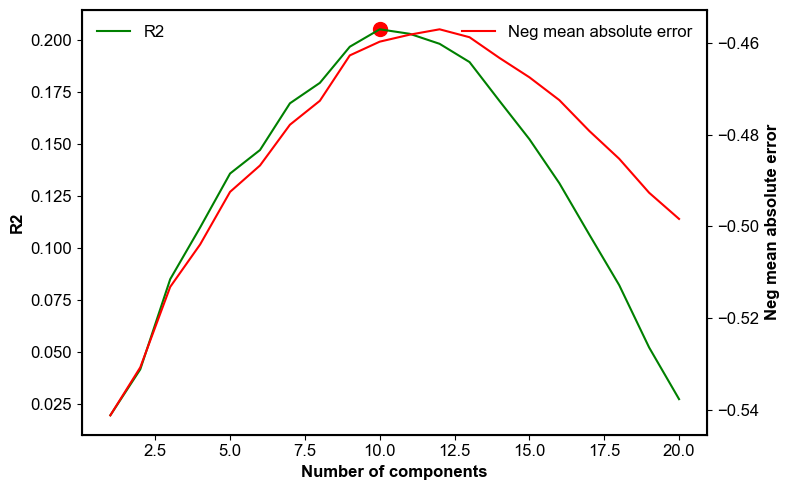

In [9]:
# Plot the scores as a dual y-axis plot
fig, ax1 = plt.subplots(figsize=(8, 5))

ax2 = ax1.twinx()

sns.lineplot(x=n_comp, y=r2, ax=ax1, label='R2', color="green")
sns.lineplot(x=n_comp, y=neg_mean_absolute_error, ax=ax2, label='Neg mean absolute error', color="red")

ax1.set_xlabel('Number of components', fontsize=12, fontweight='bold')
ax1.set_ylabel('R2', fontsize=12, fontweight='bold')
ax2.set_ylabel('Neg mean absolute error', fontsize=12, fontweight='bold')

ax1.legend(loc='upper left', fontsize=12, frameon=False)
ax1.tick_params(axis='both', labelsize=12)
ax2.legend(loc='upper right', fontsize=12, frameon=False)
ax2.tick_params(axis='both', labelsize=12)

ax1.spines[["top", "bottom", "left", "right"]].set_linewidth(1.5)

# Add a dot at the optimal number of components
ax1.scatter(np.argmax(r2) + 1, r2[np.argmax(r2)], color="red", marker='o', s=100)

plt.tight_layout()
plt.show()

In [10]:
# We need to create distinct matrices of shape (n_samples, n_features) for each block
# They represent the different dimensions of the node embeddings, so we need 64 matrices
node_embeddings_blocks_train = []
for dim in range(node_embeddings_train.shape[2]):
    node_embeddings_blocks_train.append(node_embeddings_train[:, :, dim])

node_embeddings_blocks_test = []
for dim in range(node_embeddings_test.shape[2]):
    node_embeddings_blocks_test.append(node_embeddings_test[:, :, dim])

node_embeddings_blocks_val = []
for dim in range(node_embeddings_val.shape[2]):
    node_embeddings_blocks_val.append(node_embeddings_val[:, :, dim])

# Let's fit the final MBPLS model
mbpls = MBPLS(n_components=np.argmax(r2) + 1)
mbpls.fit(node_embeddings_blocks_train, age_train_df)

train_pred = mbpls.predict(node_embeddings_blocks_train)
test_pred = mbpls.predict(node_embeddings_blocks_test)
val_pred = mbpls.predict(node_embeddings_blocks_val)

r2_train = mbpls.r2_score(node_embeddings_blocks_train, age_train_df)
r2_test = mbpls.r2_score(node_embeddings_blocks_test, age_test_df)
r2_val = mbpls.r2_score(node_embeddings_blocks_val, age_val_df)

pearson_corr_train = np.corrcoef(age_train_df, train_pred.flatten())[0, 1]
pearson_corr_test = np.corrcoef(age_test_df, test_pred.flatten())[0, 1]
pearson_corr_val = np.corrcoef(age_val_df, val_pred.flatten())[0, 1]

print(f"Train metrics: R2: {r2_train:.4f}, Pearson correlation: {pearson_corr_train:.4f}")
print(f"Test metrics: R2: {r2_test:.4f}, Pearson correlation: {pearson_corr_test:.4f}")
print(f"Validation metrics: R2: {r2_val:.4f}, Pearson correlation: {pearson_corr_val:.4f}")

Train metrics: R2: 0.4803, Pearson correlation: 0.6931
Test metrics: R2: 0.2186, Pearson correlation: 0.4965
Validation metrics: R2: 0.1778, Pearson correlation: 0.4540


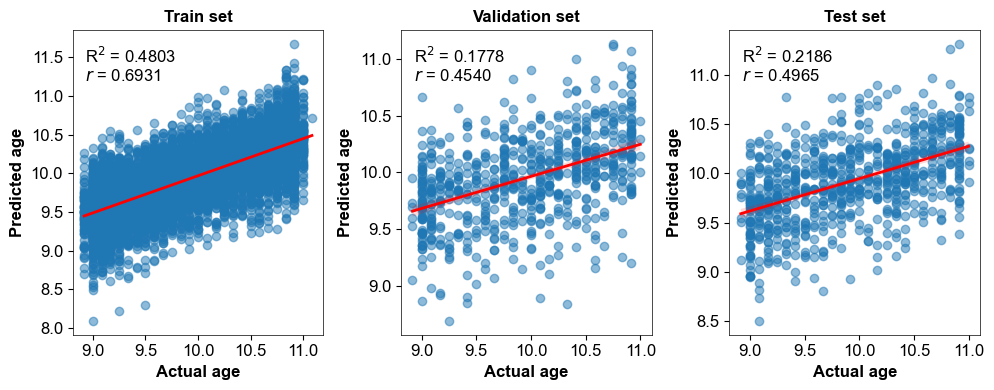

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(10, 4))

for ax, (age_df, pred, title, r2, pearson_corr) in zip(axs, [(age_train_df, train_pred, "Train set", r2_train, pearson_corr_train),  (age_val_df, val_pred, "Validation set", r2_val, pearson_corr_val), (age_test_df, test_pred, "Test set", r2_test, pearson_corr_test)]):
    sns.regplot(x=age_df, y=pred, ax=ax, scatter_kws={"alpha": 0.5}, line_kws={"color": "red", "lw": 2})
    ax.set_xlabel("Actual age", fontsize=12, fontweight='bold')
    ax.set_ylabel("Predicted age", fontsize=12, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')

    ax.text(0.05, 0.95, f"R$^2$ = {r2:.4f}\n$r$ = {pearson_corr:.4f}", transform=ax.transAxes, fontsize=12, verticalalignment='top', horizontalalignment='left')

    ax.spines[["top", "bottom", "left", "right"]].set_linewidth(0.5)
    ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.show()

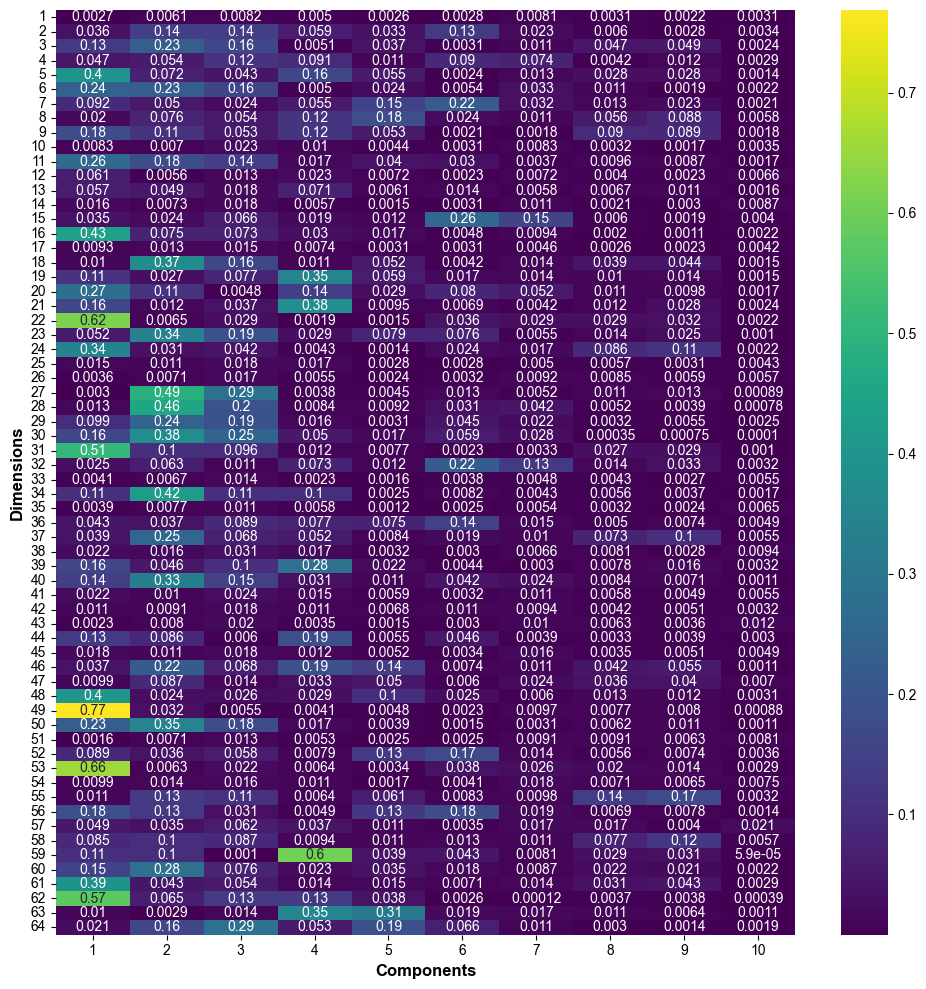

In [17]:
# Plot the explained variance for each block as a heatmap
var = mbpls.explained_var_xblocks_

fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(var, annot=True, cmap='viridis', ax=ax, xticklabels=[i for i in range(1, var.shape[1]+1)],
            yticklabels=[i for i in range(1, var.shape[0]+1)])
ax.set_xlabel('Components', fontsize=12, fontweight='bold')
ax.set_ylabel('Dimensions', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


In [68]:
# Due to the same thing, but with externalizing behaviors. 
nihtb_df = pd.read_csv(f"{data_abcd}/abcd-data-release-5.1/core/neurocognition/nc_y_nihtb.csv")
nihtb_df = nihtb_df[nihtb_df["eventname"] == "baseline_year_1_arm_1"]
nihtb_df.loc[:, "src_subject_id"] = nihtb_df["src_subject_id"].apply(lambda x: "sub-" + x.replace("_", ""))

nihtb_df = nihtb_df[["src_subject_id", "nihtbx_totalcomp_agecorrected"]]
nihtb_df.dropna(inplace=True)

# Keep only subjects that have both an embedding and a CBCL score, in embedding order.
index = np.asarray(index)
nihtb_df = nihtb_df.drop_duplicates("src_subject_id").set_index("src_subject_id")

def aligned_split(split_subs):
    mask = np.isin(index, split_subs) & np.isin(index, nihtb_df.index)
    subs = index[mask]
    embeddings = node_embeddings[mask]
    nihtb = nihtb_df.loc[subs].reset_index()
    assert nihtb["src_subject_id"].tolist() == subs.tolist()
    return subs, embeddings, nihtb

train_subs_nihtb, node_embeddings_train_nihtb, nihtb_df_train = aligned_split(train_subs)
test_subs_nihtb, node_embeddings_test_nihtb, nihtb_df_test = aligned_split(test_subs)
val_subs_nihtb, node_embeddings_val_nihtb, nihtb_df_val = aligned_split(val_subs)


/var/folders/23/p0fh1nrd473dtfz3cx_4g0j00000gn/T/ipykernel_59693/2555231012.py:2: DtypeWarning: Columns (49) have mixed types. Specify dtype option on import or set low_memory=False.
  nihtb_df = pd.read_csv(f"{data_abcd}/abcd-data-release-5.1/core/neurocognition/nc_y_nihtb.csv")


In [69]:
# nihtb df
nihtb_df_train = nihtb_df_train["nihtbx_totalcomp_agecorrected"]
nihtb_df_test = nihtb_df_test["nihtbx_totalcomp_agecorrected"]
nihtb_df_val = nihtb_df_val["nihtbx_totalcomp_agecorrected"]

# Let's fit a multi-block PLSR model using mbpls
n_comp = range(1, 21)

# Run cross-validation to find the optimal number of components
metrics = ["explained_variance", "r2", "neg_mean_absolute_error"]

explained_variance_nihtb = []
r2_nihtb = []
neg_mean_absolute_error_nihtb = []
for n in n_comp:
    pls_nihtb = PLSRegression(n_components=n)
    scores = cross_validate(pls_nihtb,
        pd.DataFrame(node_embeddings_train_nihtb.reshape(node_embeddings_train_nihtb.shape[0], node_embeddings_train_nihtb.shape[1] * node_embeddings_train_nihtb.shape[2]), index=train_subs_nihtb),
        nihtb_df_train, cv=5, scoring=metrics)
    explained_variance_nihtb.append(scores['test_explained_variance'].mean())
    r2_nihtb.append(scores['test_r2'].mean())
    neg_mean_absolute_error_nihtb.append(scores['test_neg_mean_absolute_error'].mean())
    print(f"n: {n}, explained_variance_nihtb: {scores['test_explained_variance'].mean()}, r2_nihtb: {scores['test_r2'].mean()}, neg_mean_absolute_error_nihtb: {scores['test_neg_mean_absolute_error'].mean()}")

n: 1, explained_variance_nihtb: 0.04321854929789544, r2_nihtb: 0.042869095694628954, neg_mean_absolute_error_nihtb: -13.541461448102671
n: 2, explained_variance_nihtb: 0.05580517874418371, r2_nihtb: 0.05553708871389851, neg_mean_absolute_error_nihtb: -13.431098119794623
n: 3, explained_variance_nihtb: 0.08254856169667373, r2_nihtb: 0.08238745578881827, neg_mean_absolute_error_nihtb: -13.251903548872615
n: 4, explained_variance_nihtb: 0.10404645496989254, r2_nihtb: 0.10393126708394296, neg_mean_absolute_error_nihtb: -13.097677762273307
n: 5, explained_variance_nihtb: 0.12603048449341653, r2_nihtb: 0.12588848405496914, neg_mean_absolute_error_nihtb: -12.91975707086761
n: 6, explained_variance_nihtb: 0.1347897083515363, r2_nihtb: 0.13464891185056985, neg_mean_absolute_error_nihtb: -12.868508558867532
n: 7, explained_variance_nihtb: 0.13597953575058536, r2_nihtb: 0.13591133235056568, neg_mean_absolute_error_nihtb: -12.832170017386563
n: 8, explained_variance_nihtb: 0.13639414976810643, r2_

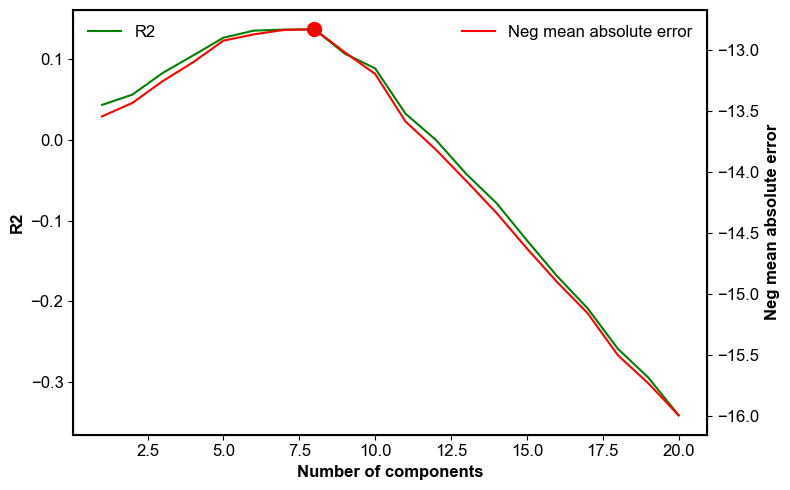

In [70]:
# Plot the scores as a dual y-axis plot
fig, ax1 = plt.subplots(figsize=(8, 5))

ax2 = ax1.twinx()

sns.lineplot(x=n_comp, y=r2_nihtb, ax=ax1, label='R2', color="green")
sns.lineplot(x=n_comp, y=neg_mean_absolute_error_nihtb, ax=ax2, label='Neg mean absolute error', color="red")

ax1.set_xlabel('Number of components', fontsize=12, fontweight='bold')
ax1.set_ylabel('R2', fontsize=12, fontweight='bold')
ax2.set_ylabel('Neg mean absolute error', fontsize=12, fontweight='bold')

ax1.legend(loc='upper left', fontsize=12, frameon=False)
ax1.tick_params(axis='both', labelsize=12)
ax2.legend(loc='upper right', fontsize=12, frameon=False)
ax2.tick_params(axis='both', labelsize=12)

ax1.spines[["top", "bottom", "left", "right"]].set_linewidth(1.5)

# Add a dot at the optimal number of components
ax1.scatter(np.argmax(r2_nihtb) + 1, r2_nihtb[np.argmax(r2_nihtb)], color="red", marker='o', s=100)

plt.tight_layout()
plt.show()

In [71]:
# We need to create distinct matrices of shape (n_samples, n_features) for each block
# They represent the different dimensions of the node embeddings, so we need 64 matrices
node_embeddings_blocks_train_nihtb = []
for dim in range(node_embeddings_train_nihtb.shape[2]):
    node_embeddings_blocks_train_nihtb.append(node_embeddings_train_nihtb[:, :, dim])

node_embeddings_blocks_test_nihtb = []
for dim in range(node_embeddings_test_nihtb.shape[2]):
    node_embeddings_blocks_test_nihtb.append(node_embeddings_test_nihtb[:, :, dim])

node_embeddings_blocks_val_nihtb = []
for dim in range(node_embeddings_val_nihtb.shape[2]):
    node_embeddings_blocks_val_nihtb.append(node_embeddings_val_nihtb[:, :, dim])

# Let's fit the final MBPLS model
mbpls_nihtb = MBPLS(n_components=np.argmax(r2_nihtb) + 1)
mbpls_nihtb.fit(node_embeddings_blocks_train_nihtb, nihtb_df_train)

train_pred_nihtb = mbpls_nihtb.predict(node_embeddings_blocks_train_nihtb)
test_pred_nihtb = mbpls_nihtb.predict(node_embeddings_blocks_test_nihtb)
val_pred_nihtb = mbpls_nihtb.predict(node_embeddings_blocks_val_nihtb)

r2_train_nihtb = mbpls_nihtb.r2_score(node_embeddings_blocks_train_nihtb, nihtb_df_train)
r2_test_nihtb = mbpls_nihtb.r2_score(node_embeddings_blocks_test_nihtb, nihtb_df_test)
r2_val_nihtb = mbpls_nihtb.r2_score(node_embeddings_blocks_val_nihtb, nihtb_df_val)

pearson_corr_train_nihtb = np.corrcoef(nihtb_df_train, train_pred_nihtb.flatten())[0, 1]
pearson_corr_test_nihtb = np.corrcoef(nihtb_df_test, test_pred_nihtb.flatten())[0, 1]
pearson_corr_val_nihtb = np.corrcoef(nihtb_df_val, val_pred_nihtb.flatten())[0, 1]

print(f"Train metrics: R2: {r2_train_nihtb:.4f}, Pearson correlation: {pearson_corr_train_nihtb:.4f}")
print(f"Test metrics: R2: {r2_test_nihtb:.4f}, Pearson correlation: {pearson_corr_test_nihtb:.4f}")
print(f"Validation metrics: R2: {r2_val_nihtb:.4f}, Pearson correlation: {pearson_corr_val_nihtb:.4f}")

Train metrics: R2: 0.3068, Pearson correlation: 0.5539
Test metrics: R2: 0.1854, Pearson correlation: 0.4383
Validation metrics: R2: 0.1080, Pearson correlation: 0.3765


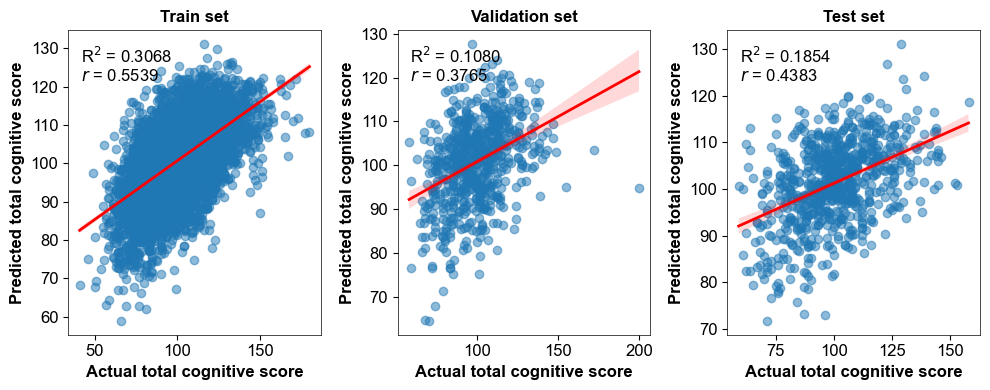

In [72]:
fig, axs = plt.subplots(1, 3, figsize=(10, 4))

for ax, (nihtb_df, pred, title, r2, pearson_corr) in zip(axs, [(nihtb_df_train, train_pred_nihtb, "Train set", r2_train_nihtb, pearson_corr_train_nihtb),  (nihtb_df_val, val_pred_nihtb, "Validation set", r2_val_nihtb, pearson_corr_val_nihtb), (nihtb_df_test, test_pred_nihtb, "Test set", r2_test_nihtb, pearson_corr_test_nihtb)]):
    sns.regplot(x=nihtb_df, y=pred, ax=ax, scatter_kws={"alpha": 0.5}, line_kws={"color": "red", "lw": 2})
    ax.set_xlabel("Actual total cognitive score", fontsize=12, fontweight='bold')
    ax.set_ylabel("Predicted total cognitive score", fontsize=12, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')

    ax.text(0.05, 0.95, f"R$^2$ = {r2:.4f}\n$r$ = {pearson_corr:.4f}", transform=ax.transAxes, fontsize=12, verticalalignment='top', horizontalalignment='left')

    ax.spines[["top", "bottom", "left", "right"]].set_linewidth(0.5)
    ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.show()

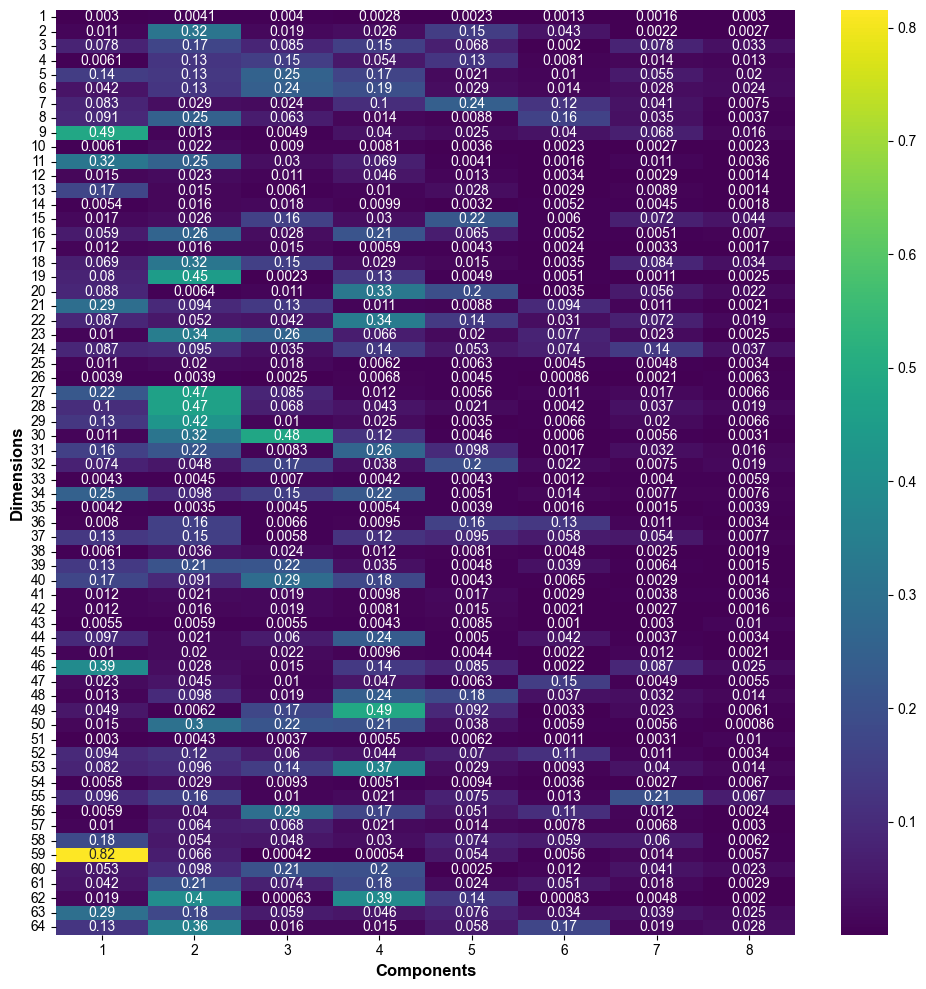

In [73]:
# Plot the explained variance for each block as a heatmap
var = mbpls_nihtb.explained_var_xblocks_

fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(var, annot=True, cmap='viridis', ax=ax, xticklabels=[i for i in range(1, var.shape[1]+1)],
            yticklabels=[i for i in range(1, var.shape[0]+1)])
ax.set_xlabel('Components', fontsize=12, fontweight='bold')
ax.set_ylabel('Dimensions', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
